SARSA baseline (last 100 episodes):
  mean discounted return: 0.358
  mean episode length: 16.11
  success rate: 0.980
  greedy evaluation (success, return, steps): (0, 0.0, nan)


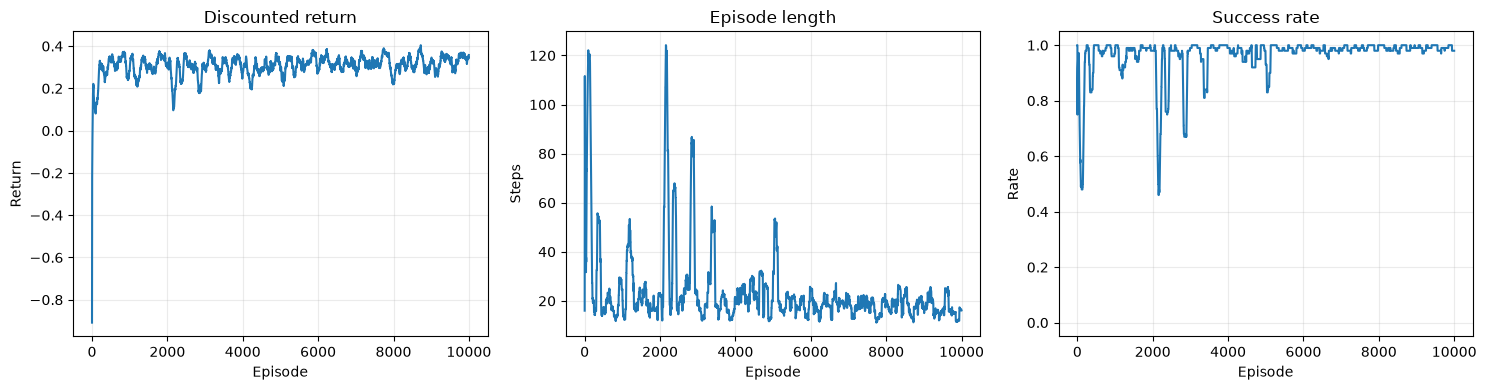

[SARSA] 5/60 experiments
[SARSA] 10/60 experiments
[SARSA] 15/60 experiments
[SARSA] 20/60 experiments
[SARSA] 25/60 experiments
[SARSA] 30/60 experiments
[SARSA] 35/60 experiments
[SARSA] 40/60 experiments
[SARSA] 45/60 experiments
[SARSA] 50/60 experiments
[SARSA] 55/60 experiments
[SARSA] 60/60 experiments
 alpha  epsilon  train_return_mean  train_return_std  train_success_mean  eval_return_mean  eval_return_std  eval_success_mean  eval_success_std  eval_steps_mean
   0.1     0.01              0.473             0.003               0.998             0.478            0.000                1.0             0.000              8.0
   0.1     0.10              0.405             0.027               1.000             0.478            0.000                1.0             0.000              8.0
   0.1     0.30              0.273             0.026               1.000             0.478            0.000                1.0             0.000              8.0
   0.1     0.50              0.129       

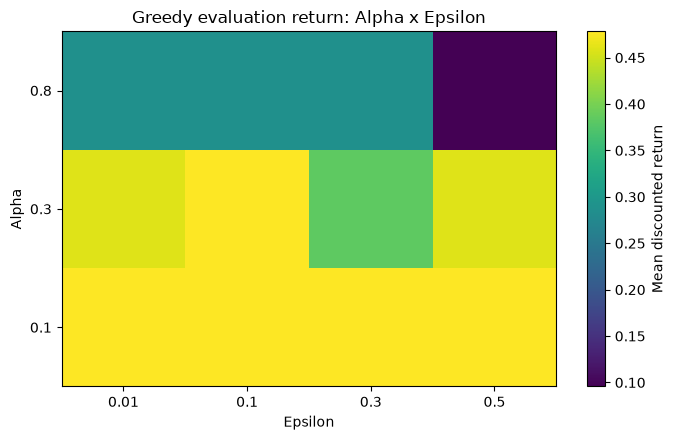

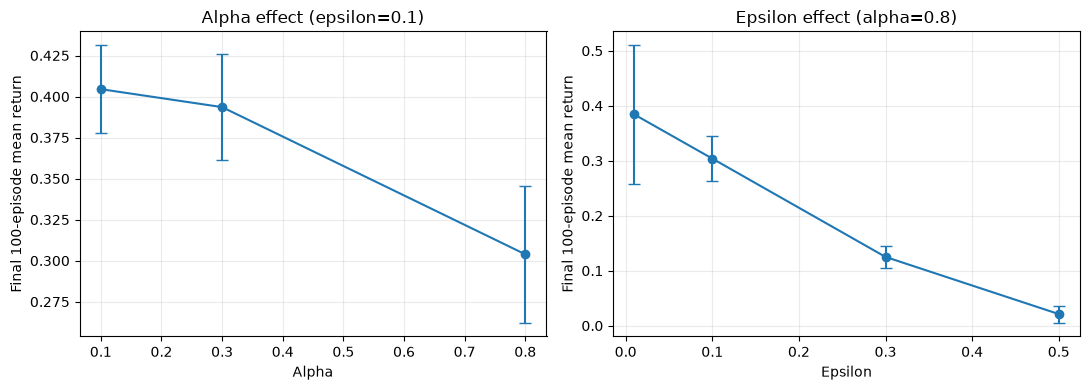

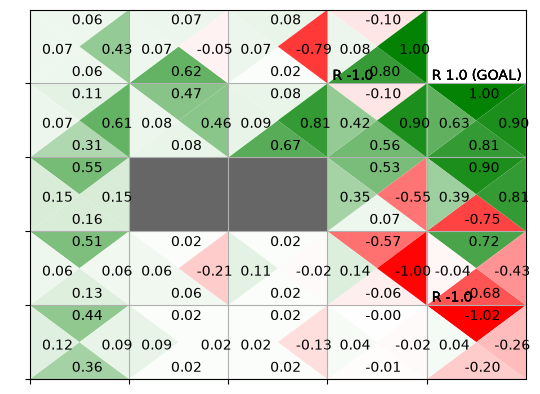

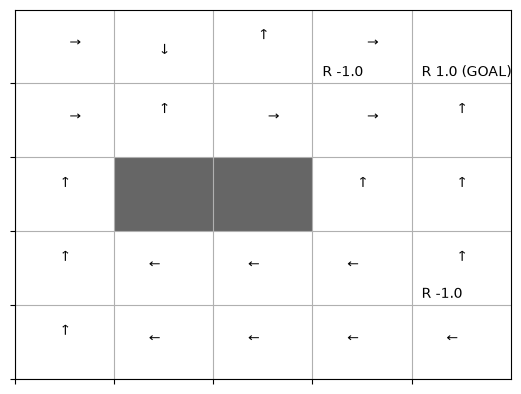

In [2]:
# GridWorld TD control experiment
# Requires the original textbook's common/gridworld.py and common/utils.py.
import os
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Keep the existing course-project folder structure.
sys.path.append(os.path.abspath('..'))
from common.gridworld import GridWorld
from common.utils import greedy_probs

GAMMA = 0.9
BASELINE_EPISODES = 10000
SWEEP_EPISODES = 3000
MAX_STEPS = 200
ALPHAS = [0.1, 0.3, 0.8]
EPSILONS = [0.01, 0.1, 0.3, 0.5]
SEEDS = range(5)

class SarsaAgent:
    def __init__(self, alpha=0.8, epsilon=0.1, gamma=GAMMA):
        self.alpha = alpha
        self.epsilon = epsilon
        self.gamma = gamma
        self.action_size = 4
        self.Q = defaultdict(float)
        self.pi = defaultdict(
            lambda: {a: 1 / self.action_size for a in range(self.action_size)}
        )

    def get_action(self, state):
        probs = self.pi[state]
        return int(np.random.choice(list(probs), p=list(probs.values())))

    def update(self, state, action, reward, next_state, next_action, done):
        next_q = 0.0 if done else self.Q[next_state, next_action]
        target = reward + self.gamma * next_q
        self.Q[state, action] += self.alpha * (target - self.Q[state, action])
        self.pi[state] = greedy_probs(self.Q, state, self.epsilon)

def train(alpha=0.8, epsilon=0.1, episodes=BASELINE_EPISODES,
          seed=42, max_steps=MAX_STEPS):
    np.random.seed(seed)
    env = GridWorld()
    agent = SarsaAgent(alpha=alpha, epsilon=epsilon)
    returns = np.zeros(episodes)
    lengths = np.zeros(episodes, dtype=int)
    successes = np.zeros(episodes, dtype=int)

    for ep in range(episodes):
        state = env.reset()
        action = agent.get_action(state)

        for t in range(max_steps):
            next_state, reward, done = env.step(action)
            next_action = None if done else agent.get_action(next_state)
            agent.update(state, action, reward, next_state, next_action, done)
            returns[ep] += (agent.gamma ** t) * reward
            lengths[ep] = t + 1

            if done:
                successes[ep] = 1
                break
            state, action = next_state, next_action

    return agent, returns, lengths, successes

def evaluate_greedy(agent, max_steps=MAX_STEPS):
    """One deterministic rollout from GridWorld.reset()."""
    env = GridWorld()
    state = env.reset()
    total_return = 0.0

    for t in range(max_steps):
        action = int(np.argmax([
            agent.Q[state, a] for a in range(agent.action_size)
        ]))
        state, reward, done = env.step(action)
        total_return += (agent.gamma ** t) * reward
        if done:
            return 1, total_return, t + 1

    return 0, total_return, np.nan  # A timed-out episode is not successful.


def moving_average(values, window=100):
    return pd.Series(values).rolling(window, min_periods=1).mean()


def plot_learning_curves(returns, lengths, successes, output_dir):
    fig, axs = plt.subplots(1, 3, figsize=(15, 4))
    for ax, arr, title, ylabel in zip(
        axs,
        [returns, lengths, successes],
        ['Discounted return', 'Episode length', 'Success rate'],
        ['Return', 'Steps', 'Rate']
    ):
        ax.plot(moving_average(arr), linewidth=1.5)
        ax.set(title=title, xlabel='Episode', ylabel=ylabel)
        ax.grid(alpha=0.25)
    axs[2].set_ylim(-0.05, 1.05)
    fig.tight_layout()
    fig.savefig(output_dir / 'learning_curves.png', dpi=180)
    plt.show()
    plt.close(fig)


def parameter_sweep(algorithm, output_dir):
    records = []
    total = len(ALPHAS) * len(EPSILONS) * len(SEEDS)
    finished = 0

    for alpha in ALPHAS:
        for epsilon in EPSILONS:
            for seed in SEEDS:
                agent, returns, lengths, successes = train(
                    alpha=alpha, epsilon=epsilon,
                    episodes=SWEEP_EPISODES, seed=seed
                )
                eval_success, eval_return, eval_steps = evaluate_greedy(agent)
                records.append({
                    'algorithm': algorithm,
                    'alpha': alpha,
                    'epsilon': epsilon,
                    'seed': seed,
                    'train_return_last100': returns[-100:].mean(),
                    'train_success_last100': successes[-100:].mean(),
                    'train_steps_last100': lengths[-100:].mean(),
                    'eval_success': eval_success,
                    'eval_return': eval_return,
                    'eval_steps': eval_steps,
                })
                finished += 1
                if finished % len(SEEDS) == 0:
                    print(f'[{algorithm}] {finished}/{total} experiments')

    results = pd.DataFrame(records)
    results.to_csv(output_dir / 'sweep_raw.csv', index=False)
    summary = results.groupby(['alpha', 'epsilon']).agg(
        train_return_mean=('train_return_last100', 'mean'),
        train_return_std=('train_return_last100', 'std'),
        train_success_mean=('train_success_last100', 'mean'),
        eval_return_mean=('eval_return', 'mean'),
        eval_return_std=('eval_return', 'std'),
        eval_success_mean=('eval_success', 'mean'),
        eval_success_std=('eval_success', 'std'),
        eval_steps_mean=('eval_steps', 'mean'),
    ).reset_index()
    summary.to_csv(output_dir / 'sweep_summary.csv', index=False)
    print(summary.round(3).to_string(index=False))
    return results, summary


def plot_parameter_results(summary, output_dir):
    matrix = summary.pivot(index='alpha', columns='epsilon',
                           values='eval_return_mean')
    fig, ax = plt.subplots(figsize=(7, 4.5))
    image = ax.imshow(matrix.to_numpy(), aspect='auto', origin='lower')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(xlabel='Epsilon', ylabel='Alpha',
           title='Greedy evaluation return: Alpha x Epsilon')
    fig.colorbar(image, ax=ax, label='Mean discounted return')
    fig.tight_layout()
    fig.savefig(output_dir / 'alpha_epsilon_heatmap.png', dpi=180)
    plt.show()
    plt.close(fig)

    # Controlled 1D comparisons: fix epsilon (alpha test), fix alpha (epsilon test).
    fixed_epsilon, fixed_alpha = 0.1, 0.8
    a = summary[np.isclose(summary['epsilon'], fixed_epsilon)]
    e = summary[np.isclose(summary['alpha'], fixed_alpha)]
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    axs[0].errorbar(a['alpha'], a['train_return_mean'],
                    yerr=a['train_return_std'], marker='o', capsize=4)
    axs[0].set(title=f'Alpha effect (epsilon={fixed_epsilon})',
               xlabel='Alpha', ylabel='Final 100-episode mean return')
    axs[1].errorbar(e['epsilon'], e['train_return_mean'],
                    yerr=e['train_return_std'], marker='o', capsize=4)
    axs[1].set(title=f'Epsilon effect (alpha={fixed_alpha})',
               xlabel='Epsilon', ylabel='Final 100-episode mean return')
    for ax in axs:
        ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(output_dir / 'alpha_epsilon_effects.png', dpi=180)
    plt.show()
    plt.close(fig)

def main():
    output_dir = Path('td_results') / 'sarsa'
    output_dir.mkdir(parents=True, exist_ok=True)

    agent, returns, lengths, successes = train(seed=42)
    print('SARSA baseline (last 100 episodes):')
    print(f'  mean discounted return: {returns[-100:].mean():.3f}')
    print(f'  mean episode length: {lengths[-100:].mean():.2f}')
    print(f'  success rate: {successes[-100:].mean():.3f}')
    print(f'  greedy evaluation (success, return, steps): '
          f'{evaluate_greedy(agent)}')
    plot_learning_curves(returns, lengths, successes, output_dir)
    _, summary = parameter_sweep('SARSA', output_dir)
    plot_parameter_results(summary, output_dir)

    # Original assignment output: state-action Q-values and greedy policy.
    GridWorld().render_q(agent.Q)


# Execute all experiments and render all results from this single cell.
main()
